# Imports and Seeding

In [106]:
import gzip
import struct
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
import matplotlib.pyplot as plt
import math
import random

In [108]:
SEED = 9

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)

seed_everything(SEED)

# **Subsection 1** -- `Preparing and Visualizing Dataset`

In [ ]:
def read_idx_images(path):
    path = Path(path)
    with gzip.open(path, "rb") as f:
        magic, num_images, rows, cols = struct.unpack(">IIII", f.read(16))
        assert magic == 2051, f"Bad magic number for images: {magic}"
        data = torch.frombuffer(f.read(), dtype=torch.uint8)

    images = data.reshape(num_images, rows, cols).float() / 255.0
    return images  # shape: [N, 28, 28]


def read_idx_labels(path):
    path = Path(path)
    with gzip.open(path, "rb") as f:
        magic, num_labels = struct.unpack(">II", f.read(8))
        assert magic == 2049, f"Bad magic number for labels: {magic}"
        labels = torch.frombuffer(f.read(), dtype=torch.uint8).long()

    assert len(labels) == num_labels
    return labels  # shape: [N]

In [ ]:
class SpuriousBinaryMNIST(Dataset):

    def __init__(
        self,
        image_path,
        label_path,
        split="train",
        train_correlation=0.95,
        seed=0,
    ):
        assert split in {"train", "test"}

        self.images_gray = read_idx_images(image_path)
        self.digit_labels = read_idx_labels(label_path)

        assert len(self.images_gray) == len(self.digit_labels)

        self.binary_labels = (self.digit_labels >= 5).long()
        self.split = split

        g = torch.Generator().manual_seed(seed)

        if split == "train":
            aligned = torch.rand(len(self.binary_labels), generator=g) < train_correlation

            base_color = self.binary_labels.clone()

            self.color_ids = torch.where(aligned, base_color, 1 - base_color)

        else:
            # reversed correlation with probability 100%
            # class 0 -> green, class 1 -> red
            self.color_ids = 1 - self.binary_labels

        self.images_rgb = self._colorize(self.images_gray, self.color_ids)

    def _colorize(self, gray_images, color_ids):
        n, h, w = gray_images.shape
        rgb = torch.zeros(n, 3, h, w)

        red_mask = color_ids == 0
        green_mask = color_ids == 1

        rgb[red_mask, 0] = gray_images[red_mask]
        rgb[green_mask, 1] = gray_images[green_mask]

        return rgb

    def __len__(self):
        return len(self.binary_labels)

    def __getitem__(self, idx):
        x = self.images_rgb[idx]
        y = self.binary_labels[idx]
        digit = self.digit_labels[idx]
        color = self.color_ids[idx]

        return x, y, digit, color

In [ ]:
def plot_random_examples(dataset, title, num_images=10):
    indices = torch.randperm(len(dataset))[:num_images]

    fig, axes = plt.subplots(5, num_images // 5, figsize=(12, 5))
    axes = axes.flatten()

    for ax, idx in zip(axes, indices):
        image, binary_label, digit_label, color_id = dataset[idx]

        # Convert [3, 28, 28] -> [28, 28, 3] for matplotlib
        image_np = image.permute(1, 2, 0).numpy()

        color_name = "red" if color_id.item() == 0 else "green"

        ax.imshow(image_np)
        ax.set_title(
            f"y={binary_label.item()} | digit={digit_label.item()}\n{color_name}"
        )
        ax.axis("off")

    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()



def plot_minority_examples(dataset, title="Minority examples", num_images=20, seed=0):
    
    minority_indices = []

    for i in range(len(dataset)):
        _, y, digit, color = dataset[i]
        
        if color.item() != y.item():
            minority_indices.append(i)

    print(f"Number of minority examples: {len(minority_indices)} / {len(dataset)}")
    print(f"Minority fraction: {len(minority_indices) / len(dataset):.4f}")

    if len(minority_indices) == 0:
        print("No minority examples found.")
        return

    g = torch.Generator().manual_seed(seed)
    minority_indices = torch.tensor(minority_indices)

    num_images = min(num_images, len(minority_indices))
    selected = minority_indices[torch.randperm(len(minority_indices), generator=g)[:num_images]]

    ncols = min(5, num_images)
    nrows = math.ceil(num_images / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 2.8 * nrows))

    if num_images == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for ax, idx in zip(axes, selected):
        image, binary_label, digit_label, color_id = dataset[idx.item()]

        image_np = image.permute(1, 2, 0).numpy()

        color_name = "red" if color_id.item() == 0 else "green"

        ax.imshow(image_np)
        ax.set_title(
            f"y={binary_label.item()} | digit={digit_label.item()}\n{color_name}"
        )
        ax.axis("off")

    for ax in axes[num_images:]:
        ax.axis("off")

    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

## Data Loading and Visualization

Train size: 60000
Test size: 10000
One image shape: torch.Size([3, 28, 28])
Binary label: 1
Original digit: 5
Color id: 1 (0=red, 1=green)


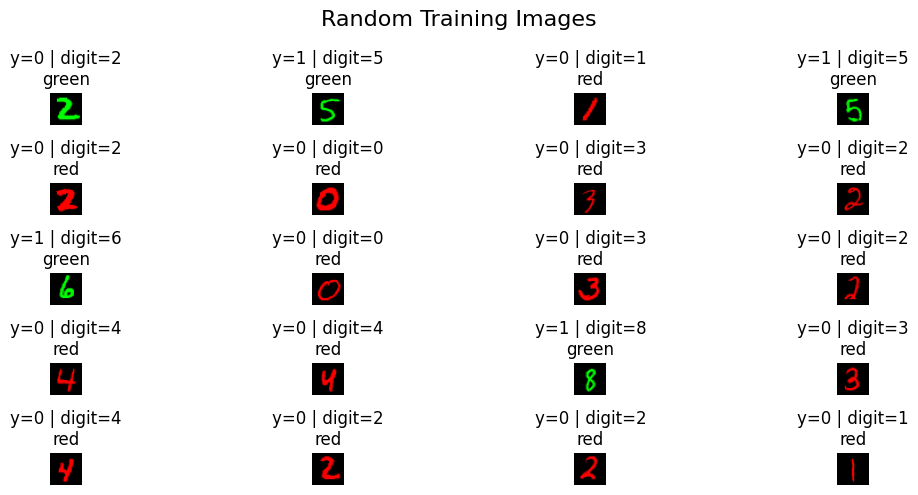

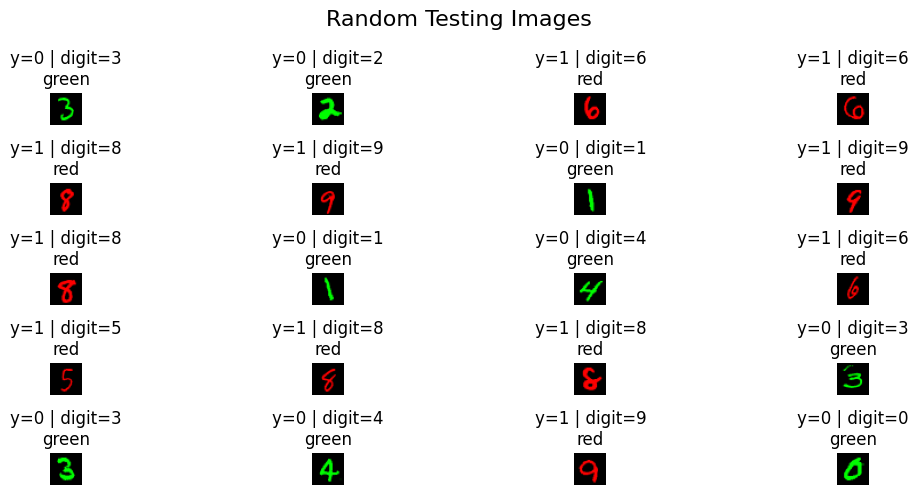

Number of minority examples: 3006 / 60000
Minority fraction: 0.0501


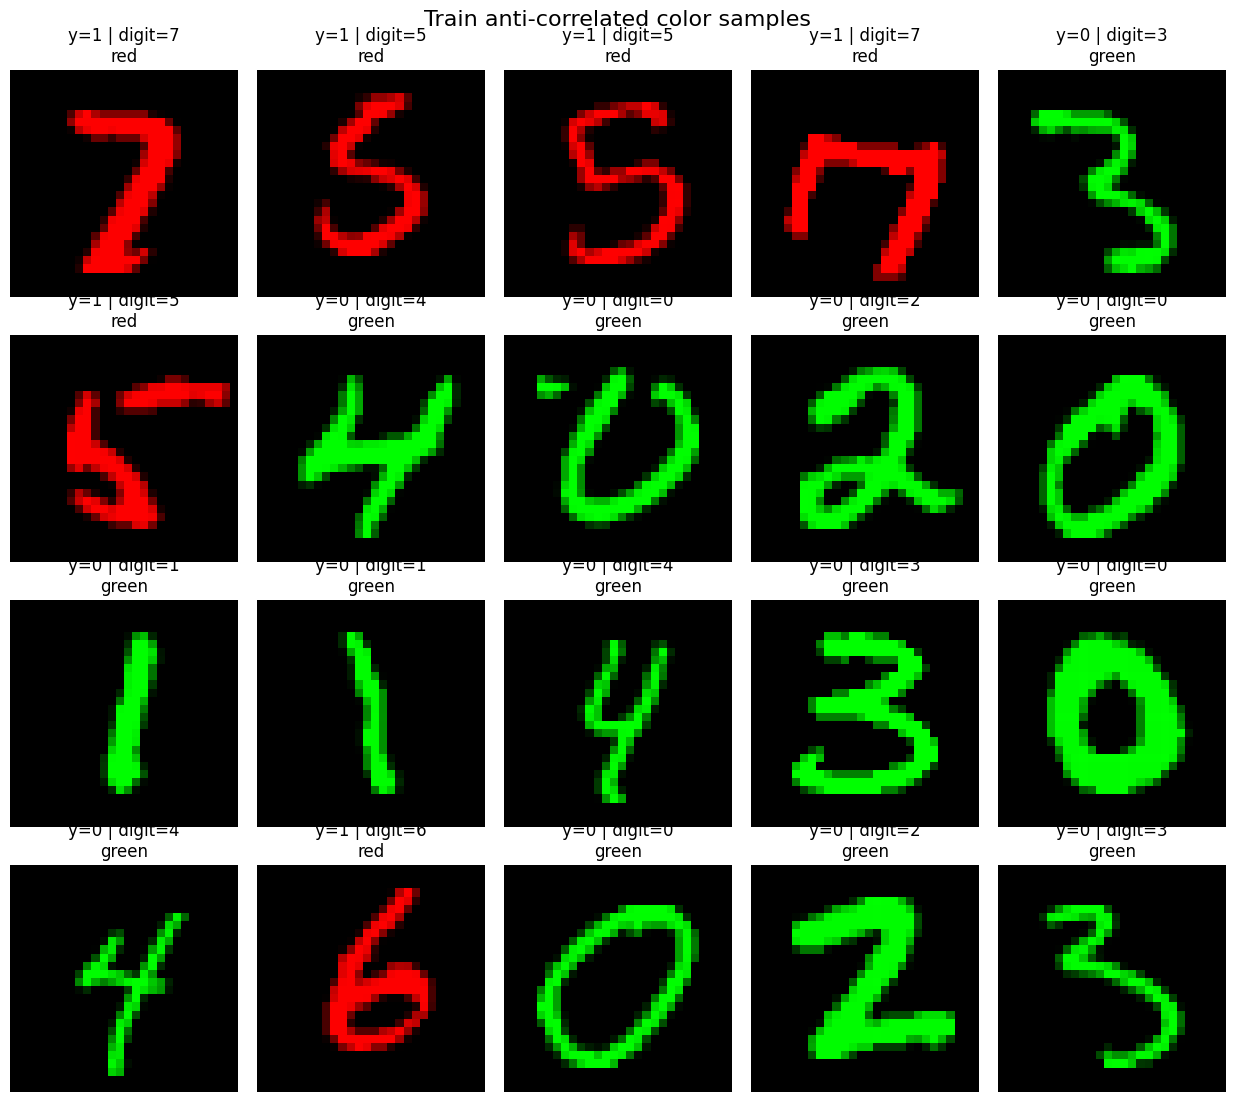

In [ ]:
DATA_DIR = Path("Mnist")
batch_size = 128

train_dataset = SpuriousBinaryMNIST(
    image_path=DATA_DIR / "train-images-idx3-ubyte.gz",
    label_path=DATA_DIR / "train-labels-idx1-ubyte.gz",
    split="train",
    train_correlation=0.95,
    seed=SEED,
)

test_dataset = SpuriousBinaryMNIST(
    image_path=DATA_DIR / "t10k-images-idx3-ubyte.gz",
    label_path=DATA_DIR / "t10k-labels-idx1-ubyte.gz",
    split="test",
    seed=SEED,
)

g_train = torch.Generator()
g_train.manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=batch_size, generator=g_train, shuffle=True)

g_test = torch.Generator()
g_test.manual_seed(SEED)

test_loader = DataLoader(test_dataset, batch_size=batch_size, generator=g_test, shuffle=False)


print("Train size:", len(train_dataset))
print("Test size:", len(test_dataset))

x, y, digit, color = train_dataset[0]
print("One image shape:", x.shape)
print("Binary label:", y.item())
print("Original digit:", digit.item())
print("Color id:", color.item(), "(0=red, 1=green)")

plot_random_examples(train_dataset, "Random Training Images", 20)
plot_random_examples(test_dataset, "Random Testing Images", 20)

plot_minority_examples(train_dataset,title="Train anti-correlated color samples", num_images=20,seed=42)

# **Subsection 2** -- `Training base model with ERM`

## Base model

In [121]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        return self.net(x)


@torch.no_grad()
def evaluate(model, dataloader, device, criterion):
    model.eval()

    correct = 0
    total = 0
    total_loss = 0.0

    for x, y, _, _ in dataloader:
        x = x.to(device)
        y = y.to(device)

        logits = model(x)
        loss = criterion(logits, y)

        preds = logits.argmax(dim=1)

        correct += (preds == y).sum().item()
        total += y.size(0)
        total_loss += loss.item() * y.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy

def train_model(
    model,
    train_loader,
    test_loader,
    device,
    num_epochs=10,
    lr=1e-3,
    title="ERM",
    criterion=None,
):
    
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(num_epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for x, y, _, _ in train_loader:
            x = x.to(device)
            y = y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * y.size(0)

            preds = logits.argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        test_loss, test_acc = evaluate(model, test_loader, device, criterion)

        print(
            f"{title} | Epoch [{epoch + 1:02d}/{num_epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_acc * 100:.2f}%"
        )

In [122]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

seed_everything(SEED)
model = MLP().to(device)

Using device: cuda


In [123]:
# with 10 epochs 87% accuracy was achieved on test set but wrongly train sampledata was only 170
# so upsampling with U = 50 would not help
train_model(
    model = model,
    train_loader= train_loader,
    test_loader= test_loader,
    device= device,
    num_epochs= 2,
    lr= 1e-3
 )

ERM | Epoch [01/2] Train Loss: 0.1408 | Train Acc: 95.50% | Test Loss: 1.3106 | Test Acc: 31.51%
ERM | Epoch [02/2] Train Loss: 0.0844 | Train Acc: 97.02% | Test Loss: 0.8713 | Test Acc: 64.49%


# **Subsection 3** -- `Extracting the Error Set`

In [124]:
@torch.no_grad()
def get_error_set(model, train_dataset, device, batch_size=128):
    """
    Returns:
        error_set: list of original training indices
                   that the model wrongly classified.
    """

    loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    model.eval()

    error_set = []
    start_idx = 0

    for x, y, _, _ in loader:
        x = x.to(device)
        y = y.to(device)

        logits = model(x)
        preds = logits.argmax(dim=1)

        wrong_mask = preds != y

        batch_size_actual = y.size(0)

        batch_indices = torch.arange(
            start_idx,
            start_idx + batch_size_actual,
        )

        wrong_indices = batch_indices[wrong_mask.cpu()]
        error_set.extend(wrong_indices.tolist())

        start_idx += batch_size_actual

    return error_set

In [125]:
error_set = get_error_set(
    model = model,
    train_dataset= train_dataset,
    device=device
)

In [126]:
len(error_set)

1208

# **Subsection 4** -- `Upsampling and creating a new dataset`

In [ ]:
def make_upsampled_dataset(train_dataset, error_set, U=50):
    
    all_indices = list(range(len(train_dataset)))

    upsampled_error_indices = error_set * U

    new_train_indices = all_indices + upsampled_error_indices

    new_train_dataset = Subset(train_dataset, new_train_indices)

    return new_train_dataset#, new_train_indices

New Train size: 120400
One image shape: torch.Size([3, 28, 28])
Binary label: 1
Original digit: 5
Color id: 1 (0=red, 1=green)


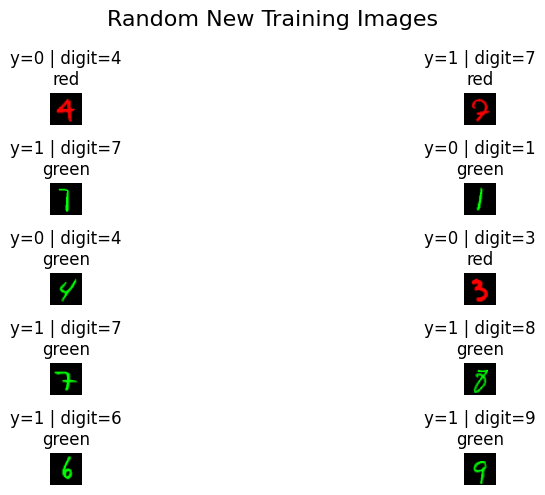

In [ ]:
g_train_new = torch.Generator()
g_train_new.manual_seed(SEED)

new_train_dataset = make_upsampled_dataset(train_dataset, error_set, U=50)
new_train_loader = DataLoader(new_train_dataset, batch_size=batch_size, generator=g_train_new, shuffle=True)

print("New Train size:", len(new_train_dataset))

x, y, digit, color = new_train_dataset[0]
print("One image shape:", x.shape)
print("Binary label:", y.item())
print("Original digit:", digit.item())
print("Color id:", color.item(), "(0=red, 1=green)")

plot_random_examples(new_train_dataset, "Random New Training Images", 10)

# **Subsection 5** -- `Training on the new data JTT style`

In [130]:
new_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", new_device)

seed_everything(SEED)
second_model = MLP().to(new_device)

Using device: cuda


In [131]:
train_model(
    model = second_model,
    train_loader= new_train_loader,
    test_loader= test_loader,
    device= new_device,
    num_epochs= 3,
    title= "JTT",
    lr= 1e-3
 )

JTT | Epoch [01/3] Train Loss: 0.1519 | Train Acc: 94.22% | Test Loss: 0.3479 | Test Acc: 88.70%
JTT | Epoch [02/3] Train Loss: 0.0215 | Train Acc: 99.48% | Test Loss: 0.4470 | Test Acc: 87.63%
JTT | Epoch [03/3] Train Loss: 0.0094 | Train Acc: 99.77% | Test Loss: 0.4728 | Test Acc: 89.03%


# **Subsection 6** -- `Training ERM with the new loss (GCE)`

## Training the ERM model

In [ ]:
class GCELoss(nn.Module):

    def __init__(self, q=0.7, reduction="mean", eps=1e-8):
        super().__init__()
        self.q = q
        self.reduction = reduction
        self.eps = eps

    def forward(self, logits, targets):
        probs = torch.softmax(logits, dim=1)

        # probability assigned to the true class
        p_y = probs.gather(dim=1, index=targets.view(-1, 1)).squeeze(1)

        # numerical stability
        p_y = p_y.clamp(min=self.eps, max=1.0)

        loss = (1.0 - p_y ** self.q) / self.q

        if self.reduction == "mean":
            return loss.mean()
        elif self.reduction == "sum":
            return loss.sum()
        else:
            return loss

In [133]:
seed_everything(SEED)
model_gce = MLP().to(device)

gce_criterion = GCELoss(q=0.3)

train_model(
    model=model_gce,
    train_loader=train_loader,
    test_loader=test_loader,
    device=device,
    num_epochs=2,
    lr=1e-3,
    title="GCE",
    criterion=gce_criterion,
)

GCE | Epoch [01/2] Train Loss: 0.1058 | Train Acc: 95.57% | Test Loss: 1.1251 | Test Acc: 40.57%
GCE | Epoch [02/2] Train Loss: 0.0668 | Train Acc: 97.11% | Test Loss: 0.8506 | Test Acc: 61.14%


## Getting the new error set

In [134]:
gce_error_set = get_error_set(
    model = model_gce,
    train_dataset= train_dataset,
    device=device
)

In [135]:
len(gce_error_set)

1236

## Upsampling

New Train size: 121800
One image shape: torch.Size([3, 28, 28])
Binary label: 1
Original digit: 5
Color id: 1 (0=red, 1=green)


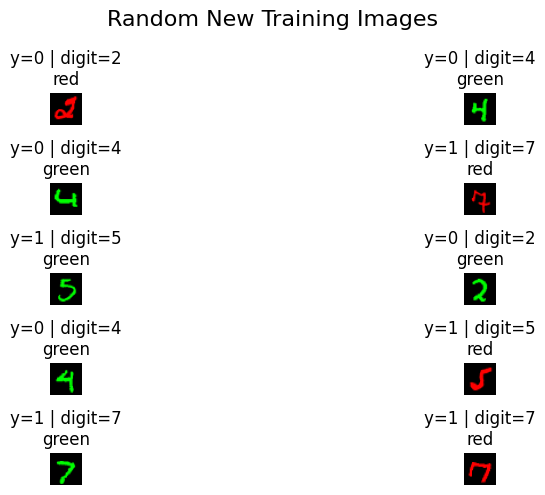

In [136]:
gce_g_train_new = torch.Generator()
gce_g_train_new.manual_seed(SEED)

gce_new_train_dataset = make_upsampled_dataset(train_dataset, gce_error_set, U=50)
gce_new_train_loader = DataLoader(gce_new_train_dataset, batch_size=batch_size, generator=gce_g_train_new, shuffle=True)

print("New Train size:", len(gce_new_train_dataset))

x, y, digit, color = gce_new_train_dataset[0]
print("One image shape:", x.shape)  # should be [3, 28, 28]
print("Binary label:", y.item())
print("Original digit:", digit.item())
print("Color id:", color.item(), "(0=red, 1=green)")

plot_random_examples(gce_new_train_dataset, "Random New Training Images", 10)

## Training the model with the GCE created data

In [146]:
new_device2 = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seed_everything(SEED)
third_model = MLP().to(new_device2)

train_model(
    model = third_model,
    train_loader= gce_new_train_loader,
    test_loader= test_loader,
    device= new_device2,
    num_epochs= 3,
    title= "JTT_gce_generated_data",
    lr= 1e-3
 )

JTT_gce_generated_data | Epoch [01/3] Train Loss: 0.1419 | Train Acc: 94.57% | Test Loss: 0.4328 | Test Acc: 85.69%
JTT_gce_generated_data | Epoch [02/3] Train Loss: 0.0211 | Train Acc: 99.50% | Test Loss: 0.4261 | Test Acc: 88.51%
JTT_gce_generated_data | Epoch [03/3] Train Loss: 0.0105 | Train Acc: 99.75% | Test Loss: 0.4124 | Test Acc: 89.93%


In [150]:
new_device3 = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seed_everything(SEED)
forth_model = MLP().to(new_device3)

train_model(
    model = forth_model,
    train_loader= gce_new_train_loader,
    test_loader= test_loader,
    device= new_device3,
    num_epochs= 3,
    criterion= gce_criterion,
    title= "JTT_gceLoss_gce_generated_data",
    lr= 1e-3
 )

JTT_gceLoss_gce_generated_data | Epoch [01/3] Train Loss: 0.1217 | Train Acc: 94.40% | Test Loss: 0.2416 | Test Acc: 87.95%
JTT_gceLoss_gce_generated_data | Epoch [02/3] Train Loss: 0.0176 | Train Acc: 99.44% | Test Loss: 0.2602 | Test Acc: 87.83%
JTT_gceLoss_gce_generated_data | Epoch [03/3] Train Loss: 0.0088 | Train Acc: 99.70% | Test Loss: 0.2048 | Test Acc: 90.72%
